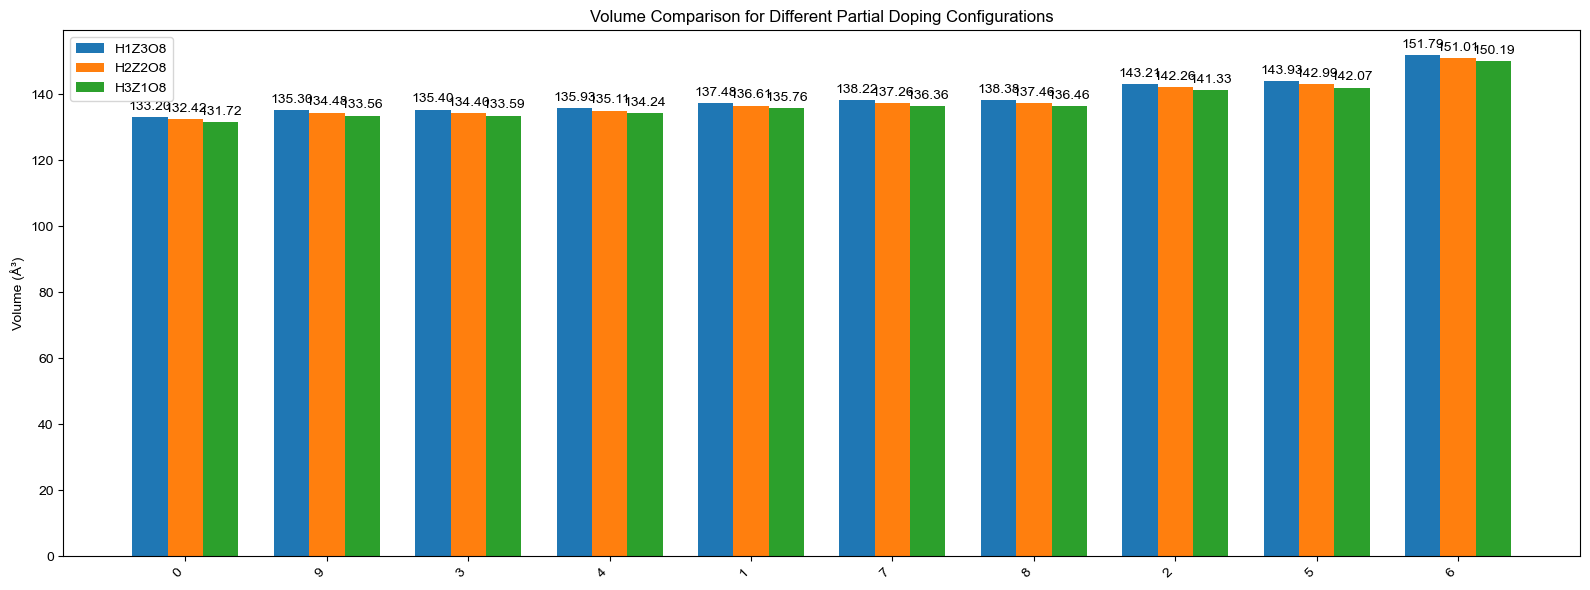

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams['font.family'] = 'Arial'

def calc_cell_volume(a, b, c, alpha, beta, gamma):
    # convert angles from degrees to radians
    alpha_r, beta_r, gamma_r = np.radians([alpha, beta, gamma])

    # the formula for the cell volume
    volume = a * b * c * np.sqrt(
        1 - np.cos(alpha_r)**2 - np.cos(beta_r)**2 - np.cos(gamma_r)**2 +
        2 * np.cos(alpha_r) * np.cos(beta_r) * np.cos(gamma_r)
    )
    return volume

file_path = 'different_partial_doping_structure_data_grouped_.csv'
df = pd.read_csv(file_path)

# calculate volumes
for method in ['H1Z3O8', 'H2Z2O8', 'H3Z1O8']:
    df[f"{method} Volume"] = df.apply(lambda row: calc_cell_volume(
        row[f"{method} a"], row[f"{method} b"], row[f"{method} c"],
        row[f"{method} alpha"], row[f"{method} beta"], row[f"{method} gamma"]
    ), axis=1)

# sort the DataFrame by H1Z3O8 Volume
df = df.sort_values(by="H1Z3O8 Volume")


# -------------------------------------------------------------------
# Add value labels
# -------------------------------------------------------------------
def add_value_labels(bars, spacing=3):
    """
    Add labels on top of bars.
    """
    for bar in bars:
        height = bar.get_height()
        plt.annotate(
            f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, spacing),
            textcoords="offset points",
            ha='center', va='bottom', fontsize=10
        )


# -------------------------------------------------------------------
# Plot the volumes in a bar chart
# -------------------------------------------------------------------

plt.figure(figsize=(16, 6))
x = np.arange(len(df))

bar_width = 0.25

bars1 = plt.bar(x - bar_width, df["H1Z3O8 Volume"], width=bar_width, label="H1Z3O8")
bars2 = plt.bar(x, df["H2Z2O8 Volume"], width=bar_width, label="H2Z2O8")
bars3 = plt.bar(x + bar_width, df["H3Z1O8 Volume"], width=bar_width, label="H3Z1O8")

# Add value labels
add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# If CSV has a column for x-axis labels
if "Formula" in df.columns:
    plt.xticks(x, df["Formula"], rotation=45, ha='right')
else:
    plt.xticks(x, df.index, rotation=45, ha='right')

plt.ylabel("Volume (Å³)")
plt.title("Volume Comparison for Different Partial Doping Configurations")
plt.legend()
plt.tight_layout()
plt.show()